# Brain Tumor Detection using Explainable AI

## Notebook 1: Data Understanding and Exploration

### Project Title
**From Genes to Decisions: An Explainable AI Framework for Brain Tumor Detection**

### Objectives
- Understand the dataset structure
- Explore class distribution
- Visualize MRI images
- Check image sizes
- Detect corrupted images (if any)
- Prepare the dataset for preprocessing

---

In [1]:
# ==========================================================
# Import Required Libraries
# ==========================================================

from pathlib import Path
import random
import warnings
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

warnings.filterwarnings("ignore")

# Display settings
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.grid"] = True

# Random seed for reproducibility
random.seed(42)
np.random.seed(42)

In [4]:
# ==========================================================
# Project Configuration
# ==========================================================

PROJECT_ROOT = Path.cwd().parent

DATASET_PATH = PROJECT_ROOT / "data" / "raw" / "Brain_Tumor_MRI_Dataset"

TRAIN_DIR = DATASET_PATH / "Training"
TEST_DIR = DATASET_PATH / "Testing"

print("Project Root :", PROJECT_ROOT)
print("Dataset Path :", DATASET_PATH)

Project Root : c:\Users\ritik\OneDrive\Desktop\From_Genes_to_Decisions
Dataset Path : c:\Users\ritik\OneDrive\Desktop\From_Genes_to_Decisions\data\raw\Brain_Tumor_MRI_Dataset


In [5]:
# ==========================================================
# Verify Dataset Structure
# ==========================================================

assert DATASET_PATH.exists(), "Dataset folder not found!"
assert TRAIN_DIR.exists(), "Training folder not found!"
assert TEST_DIR.exists(), "Testing folder not found!"

print("✅ Dataset verified successfully.")

✅ Dataset verified successfully.


In [6]:
# ==========================================================
# Load Class Names
# ==========================================================

classes = sorted([folder.name for folder in TRAIN_DIR.iterdir() if folder.is_dir()])

print("Classes Found:")
for idx, class_name in enumerate(classes, start=1):
    print(f"{idx}. {class_name}")

Classes Found:
1. glioma_tumor
2. meningioma_tumor
3. no_tumor
4. pituitary_tumor


In [7]:
# ==========================================================
# Function: Count Images
# ==========================================================

def count_images(directory: Path) -> dict:
    """
    Count the number of image files in each class folder.

    Parameters
    ----------
    directory : Path
        Path to the Training or Testing directory.

    Returns
    -------
    dict
        Dictionary containing class names and image counts.
    """

    image_counts = {}

    for class_name in classes:
        class_folder = directory / class_name

        valid_images = [
            file for file in class_folder.iterdir()
            if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]

        image_counts[class_name] = len(valid_images)

    return image_counts

In [8]:
# ==========================================================
# Dataset Summary
# ==========================================================

train_counts = count_images(TRAIN_DIR)
test_counts = count_images(TEST_DIR)

summary_df = pd.DataFrame({
    "Class": classes,
    "Training Images": [train_counts[c] for c in classes],
    "Testing Images": [test_counts[c] for c in classes]
})

summary_df["Total Images"] = (
    summary_df["Training Images"] +
    summary_df["Testing Images"]
)

summary_df

,Class,Training Images,Testing Images,Total Images
0,glioma_tumor,826,100,926
1,meningioma_tumor,822,115,937
2,no_tumor,395,105,500
3,pituitary_tumor,827,74,901


In [9]:
# ==========================================================
# Dataset Summary
# ==========================================================

train_counts = count_images(TRAIN_DIR)
test_counts = count_images(TEST_DIR)

summary_df = pd.DataFrame({
    "Class": classes,
    "Training Images": [train_counts[c] for c in classes],
    "Testing Images": [test_counts[c] for c in classes]
})

summary_df["Total Images"] = (
    summary_df["Training Images"] +
    summary_df["Testing Images"]
)

summary_df

,Class,Training Images,Testing Images,Total Images
0,glioma_tumor,826,100,926
1,meningioma_tumor,822,115,937
2,no_tumor,395,105,500
3,pituitary_tumor,827,74,901


# Sample MRI Images

Visualizing the dataset is an important step before training a Deep Learning model.

This section helps us:

- Understand visual differences between tumor classes.
- Verify that images are loaded correctly.
- Observe variations in MRI scans.

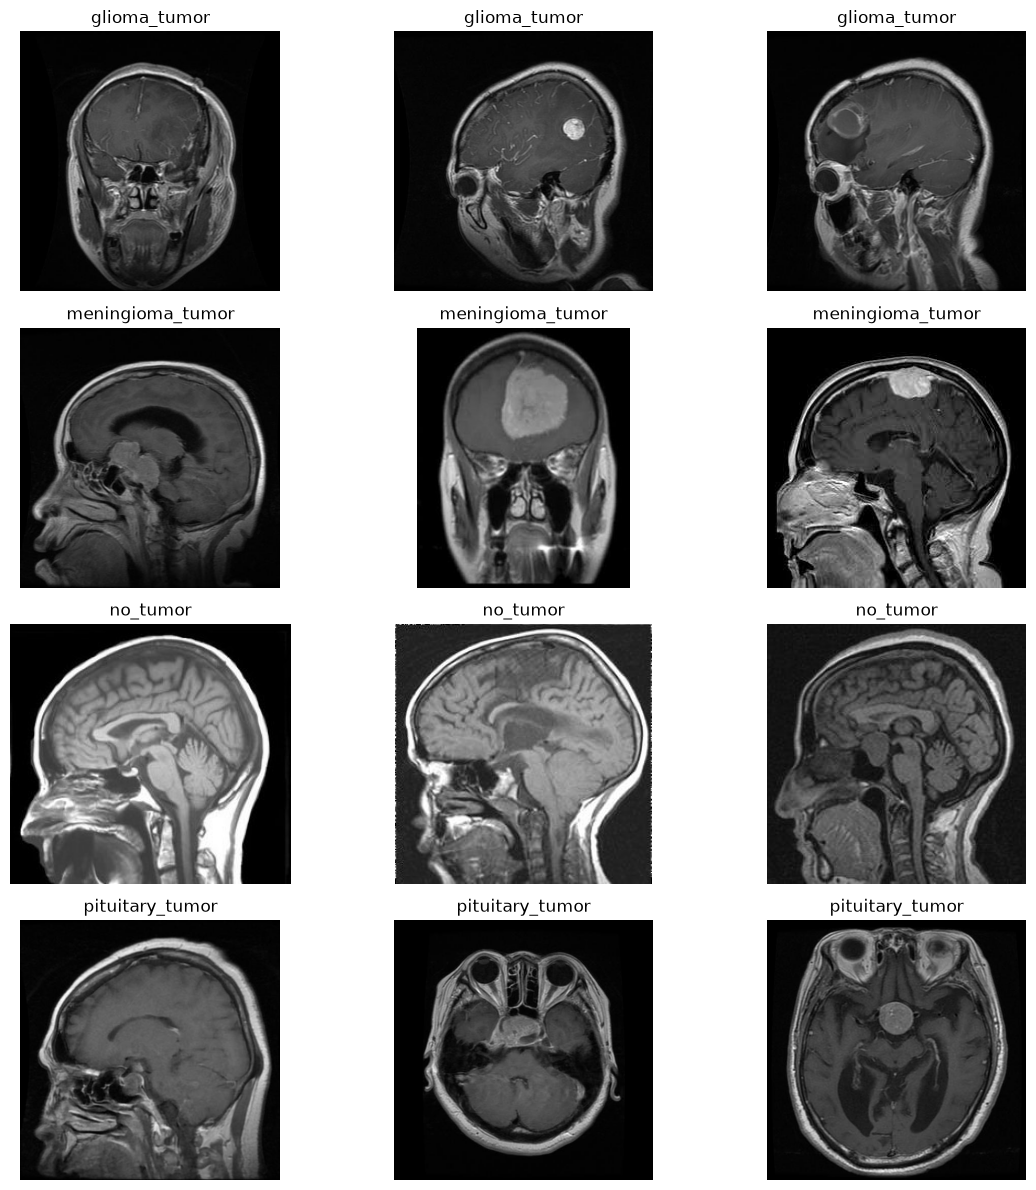

In [10]:
# ==========================================================
# Display Sample Images
# ==========================================================

fig, axes = plt.subplots(len(classes), 3, figsize=(12, 12))

for row, class_name in enumerate(classes):

    image_folder = TRAIN_DIR / class_name

    image_files = list(image_folder.glob("*"))

    selected_images = random.sample(image_files, 3)

    for col, image_path in enumerate(selected_images):

        image = Image.open(image_path)

        axes[row, col].imshow(image, cmap="gray")

        axes[row, col].set_title(class_name)

        axes[row, col].axis("off")

plt.tight_layout()

plt.show()

# Class Distribution

A balanced dataset helps Deep Learning models learn fairly from all classes.

In this section, we visualize the number of MRI images available for each class.

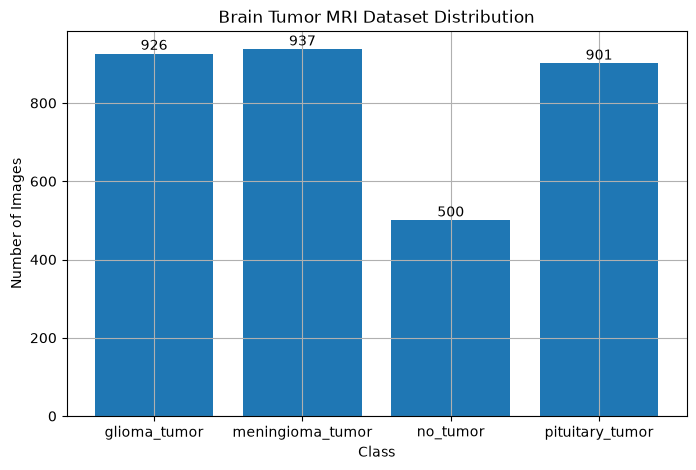

In [11]:
# ==========================================================
# Class Distribution
# ==========================================================

plt.figure(figsize=(8,5))

bars = plt.bar(
    summary_df["Class"],
    summary_df["Total Images"]
)

plt.title("Brain Tumor MRI Dataset Distribution")

plt.xlabel("Class")

plt.ylabel("Number of Images")

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 10,
        int(height),
        ha='center'
    )

plt.show()

# Image Dimension Analysis

Deep Learning models require all images to have identical dimensions.

This section analyzes image sizes across the dataset to determine whether resizing is required.

In [12]:
# ==========================================================
# Analyze Image Sizes
# ==========================================================

image_sizes = []

for class_name in classes:

    folder = TRAIN_DIR / class_name

    for image_path in folder.glob("*"):

        image = cv2.imread(str(image_path))

        if image is not None:

            h, w = image.shape[:2]

            image_sizes.append((w, h))

In [13]:
sizes_df = pd.DataFrame(
    image_sizes,
    columns=["Width", "Height"]
)

sizes_df.head()

,Width,Height
0,512,512
1,512,512
2,512,512
3,512,512
4,512,512


In [14]:
print("Number of Images Analysed :", len(sizes_df))

print()

print(sizes_df.describe())

Number of Images Analysed : 2870

             Width       Height
count  2870.000000  2870.000000
mean    480.109408   481.416376
std     110.204910   103.089398
min     180.000000   198.000000
25%     512.000000   512.000000
50%     512.000000   512.000000
75%     512.000000   512.000000
max    1375.000000  1446.000000


# Corrupted Image Detection

Corrupted images can negatively affect the training process.

This section checks whether all images can be opened successfully.

In [15]:
# ==========================================================
# Check Corrupted Images
# ==========================================================

corrupted_images = []

for class_name in classes:

    folder = TRAIN_DIR / class_name

    for image_path in folder.glob("*"):

        image = cv2.imread(str(image_path))

        if image is None:

            corrupted_images.append(image_path)

In [16]:
print(f"Corrupted Images Found : {len(corrupted_images)}")

if len(corrupted_images) > 0:

    for image in corrupted_images:

        print(image)

Corrupted Images Found : 0


In [17]:
# ==========================================================
# Save Dataset Summary
# ==========================================================

metadata_path = PROJECT_ROOT / "data" / "metadata"

metadata_path.mkdir(exist_ok=True)

summary_df.to_csv(
    metadata_path / "dataset_summary.csv",
    index=False
)

print("Dataset summary saved successfully.")

Dataset summary saved successfully.


# Conclusion

The dataset has been successfully explored and validated.

Key observations:

- Dataset structure verified successfully.
- Four classes were identified.
- MRI images were visualized.
- Image dimensions were analyzed.
- Dataset statistics were generated.
- Metadata was saved for future use.

The dataset is now ready for preprocessing.